# Week 4 Class 2 Assignment

## Assignment 1

In [7]:
import numpy as np
from PIL import Image
import glob
import matplotlib.pyplot as plt

def preprocess_image(image_path, target_size=(128, 128)):
    img = Image.open(image_path)
    img_resized = img.resize(target_size)
    img_gray = img_resized.convert("L")
    img_array = np.array(img_gray)
    return img_array

In [8]:
image_paths = sorted(glob.glob("downloadpic/*.*"))
print("Found", len(image_paths), "images")

processed_arrays = [preprocess_image(p) for p in image_paths]

processed_stack = np.stack(processed_arrays, axis=0)
print(processed_stack.shape)

Found 20 images
(20, 128, 128)


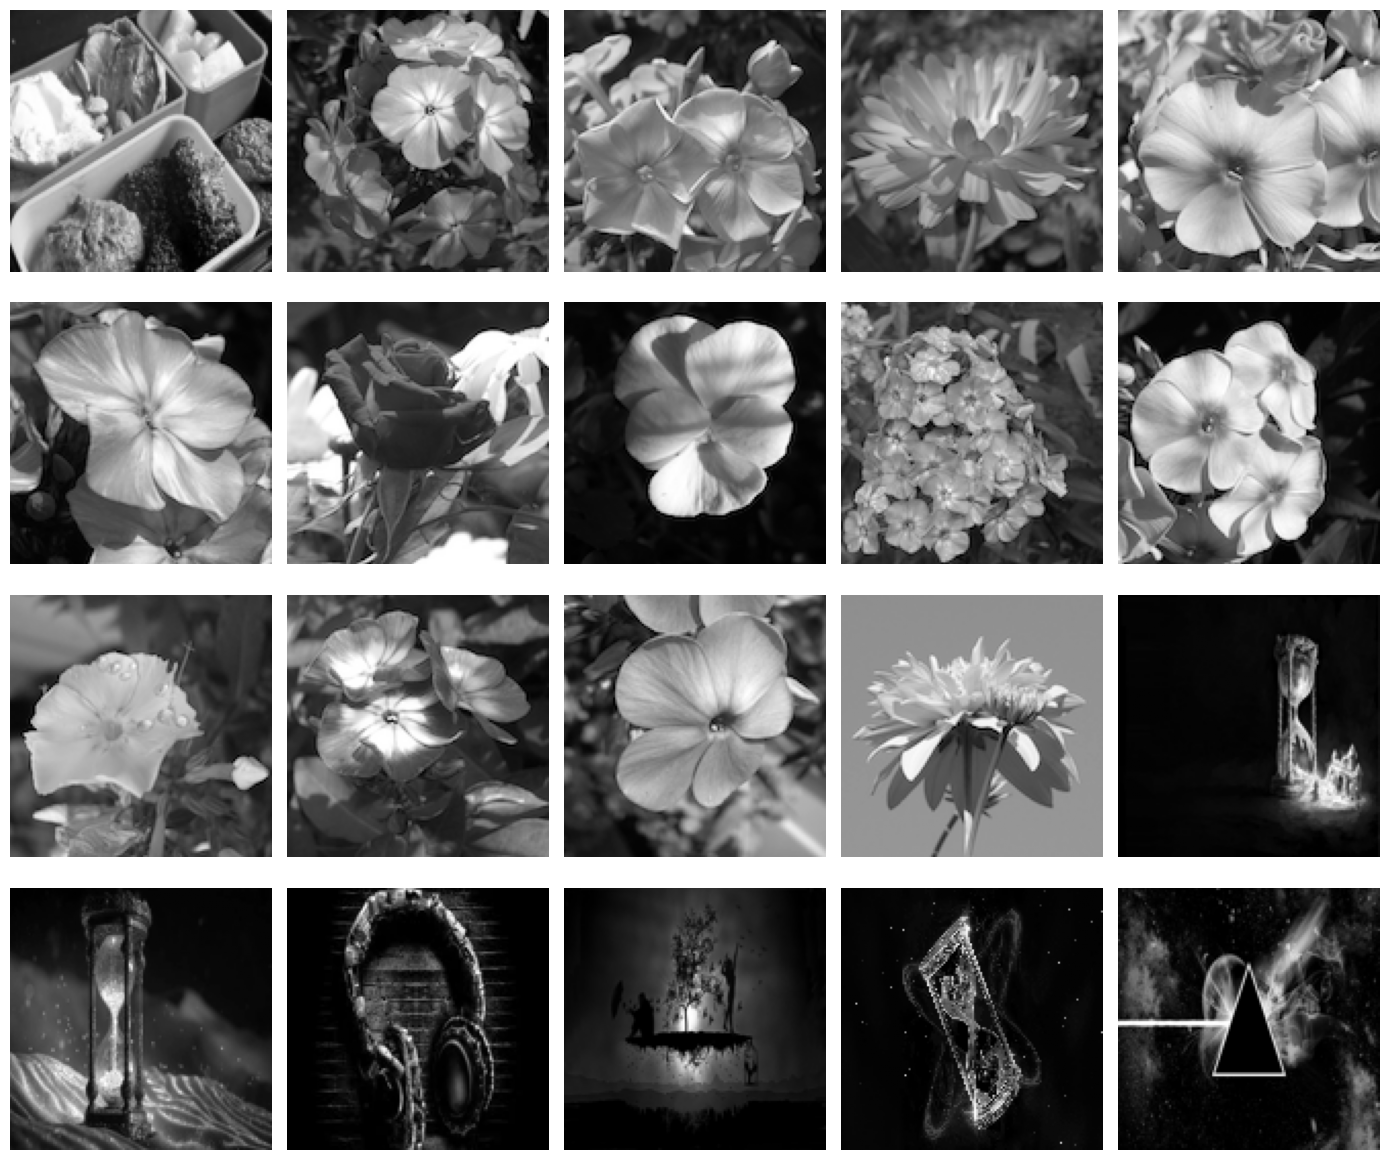

In [9]:
fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for ax, arr in zip(axes.flatten(), processed_arrays):
    ax.imshow(arr, cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Assignment 2

In [10]:
import os
from PIL import ImageDraw

def generate_noisy_satellite_dataset(folder_name="noisy_data", num_images=10):
    if not os.path.exists(folder_name):
        os.makedirs(folder_name)

    width, height = 400, 400

    base_img = Image.new('RGB', (width, height), color=(10, 10, 30))
    draw = ImageDraw.Draw(base_img)
    draw.ellipse([100, 100, 300, 300], fill=(80, 150, 200))
    for _ in range(50):
        sx, sy = np.random.randint(0, width), np.random.randint(0, height)
        draw.point((sx, sy), fill=(255, 255, 255))

    base_array = np.array(base_img, dtype=np.float32)

    for i in range(num_images):
        img_variation = base_array.copy()

        noise = np.random.normal(loc=0, scale=40, size=img_variation.shape)
        img_variation = img_variation + noise
        img_variation = np.clip(img_variation, 0, 255).astype(np.uint8)

        noisy_pil = Image.fromarray(img_variation)
        draw_noisy = ImageDraw.Draw(noisy_pil)

        start_x = np.random.randint(0, width)
        start_y = np.random.randint(0, height)
        end_x = start_x + np.random.randint(-200, 200)
        end_y = start_y + np.random.randint(-200, 200)
        draw_noisy.line([(start_x, start_y), (end_x, end_y)], fill=(255, 255, 255), width=3)

        file_path = os.path.join(folder_name, f"noisy_frame_{i+1:03d}.png")
        noisy_pil.save(file_path)

generate_noisy_satellite_dataset(num_images=100)

In [11]:
frame_paths = sorted(glob.glob("noisy_data/*.png"))
images = [np.array(Image.open(p)) for p in frame_paths]
stacked_cube = np.stack(images, axis=0)

mean_stack = np.mean(stacked_cube, axis=0).astype(np.uint8)
median_stack = np.median(stacked_cube, axis=0).astype(np.uint8)

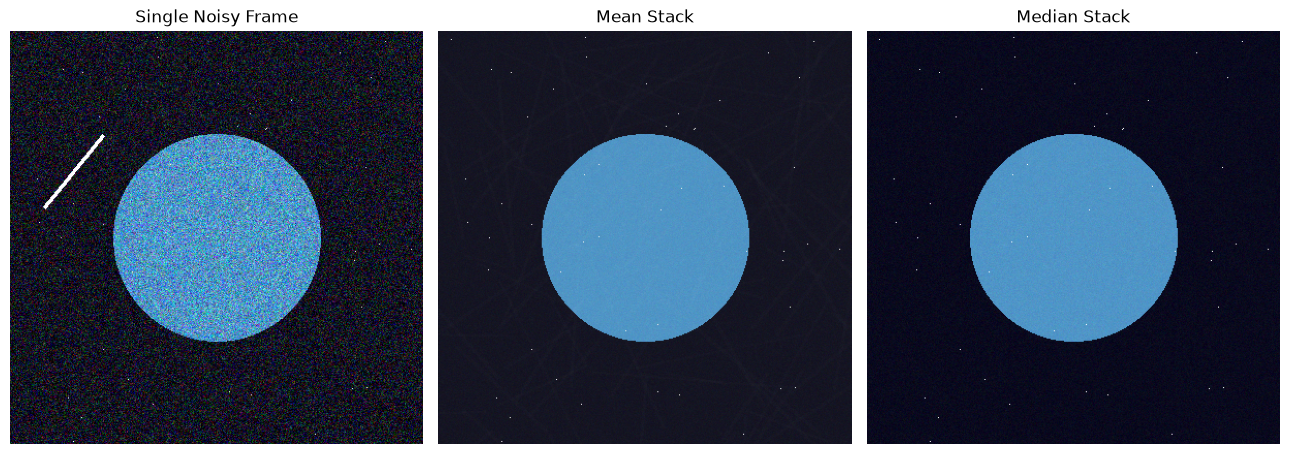

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(images[0]);      axes[0].set_title("Single Noisy Frame")
axes[1].imshow(mean_stack);     axes[1].set_title("Mean Stack")
axes[2].imshow(median_stack);   axes[2].set_title("Median Stack")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()